# Chapter 8: Tree-Based Algorithms and Ensemble Methods

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 8.*

Bab ini membahas model berbasis pohon keputusan dan metode ensemble untuk klasifikasi. Contoh menggunakan dataset bawaan scikit-learn agar notebook dapat dijalankan tanpa mengunduh data eksternal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"pandas version: {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5
pandas version: 2.2.3


> **Catatan versi.** Buku menargetkan scikit-learn 1.5+. Notebook ini memakai API umum dari `sklearn.tree`, `sklearn.ensemble`, dan `sklearn.model_selection`. Hasil angka dapat sedikit berbeda antarversi, tetapi alur analisis tetap sama.

## 1. Introduction to Decision Trees

### Ringkasan

**Decision Tree** membuat prediksi melalui serangkaian pemisahan data berdasarkan nilai fitur. Struktur pohon terdiri atas *root node*, *internal nodes*, cabang, dan *leaf nodes*. Pada klasifikasi, leaf menghasilkan kelas; pada regresi, leaf menghasilkan nilai numerik.

Kelebihannya adalah relatif mudah diinterpretasikan dan tidak memerlukan standardisasi fitur. Namun, pohon yang terlalu dalam dapat menghafal data latih (*overfitting*). Parameter seperti `max_depth` dan `min_samples_leaf` membantu mengendalikan kompleksitas.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=2024, stratify=y
)

tree_model = DecisionTreeClassifier(random_state=2024)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred_tree), 3))
print(classification_report(y_test, y_pred_tree, target_names=iris.target_names))

Akurasi: 0.911
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



**Membaca hasil.** Akurasi adalah proporsi sampel uji yang diprediksi dengan benar. `classification_report` menampilkan precision, recall, dan F1-score untuk setiap kelas. Karena pohon default dapat tumbuh cukup dalam, akurasi tinggi pada data uji tidak menjamin model akan selalu bekerja sama baiknya pada data baru.

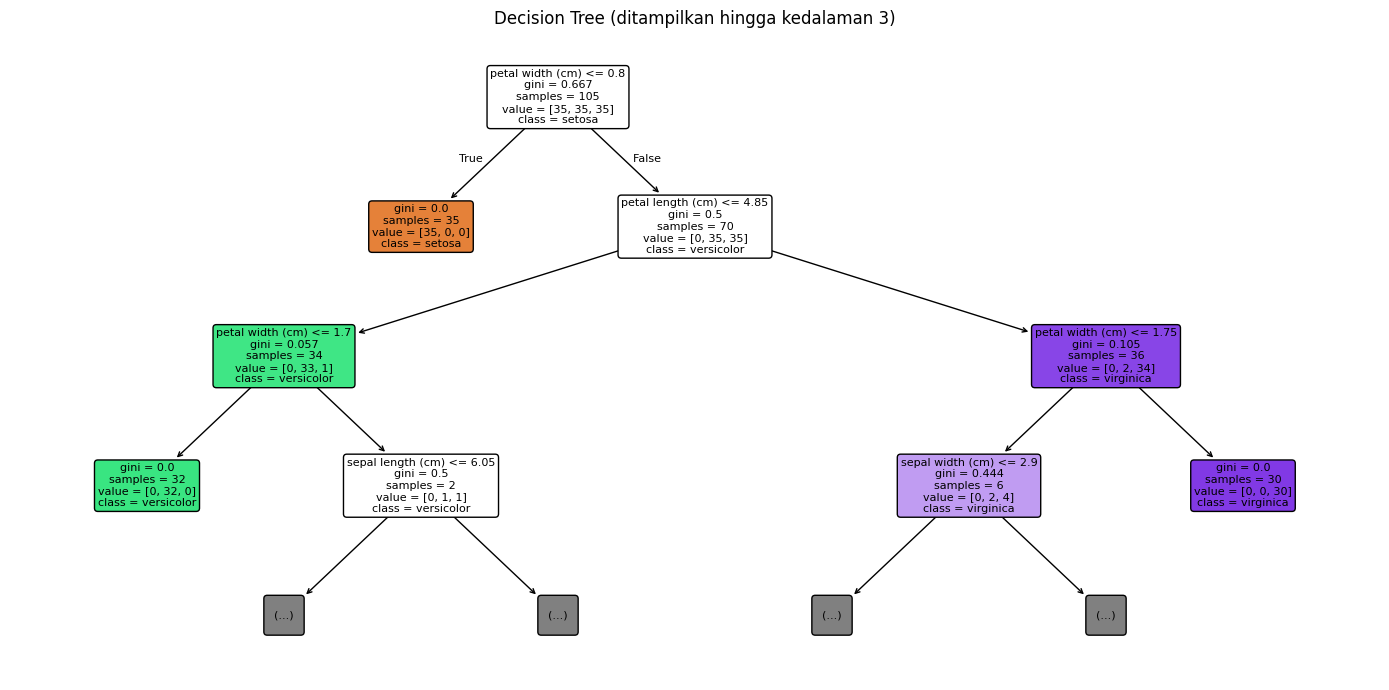

In [3]:
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (ditampilkan hingga kedalaman 3)")
plt.tight_layout()
plt.show()

**Interpretasi visualisasi.** Setiap node menampilkan aturan pemisahan, impurity, jumlah sampel, dan distribusi kelas. Visualisasi dibatasi sampai kedalaman tiga agar mudah dibaca; pembatasan tampilan ini tidak mengubah pohon yang telah dilatih.

In [4]:
# Bandingkan pohon tanpa pembatasan dengan pohon yang dibatasi
shallow_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=2024)
shallow_tree.fit(X_train, y_train)

print("Pohon default — akurasi train:", round(tree_model.score(X_train, y_train), 3))
print("Pohon default — akurasi test :", round(tree_model.score(X_test, y_test), 3))
print("Pohon terbatas — akurasi train:", round(shallow_tree.score(X_train, y_train), 3))
print("Pohon terbatas — akurasi test :", round(shallow_tree.score(X_test, y_test), 3))

Pohon default — akurasi train: 1.0
Pohon default — akurasi test : 0.911
Pohon terbatas — akurasi train: 0.971
Pohon terbatas — akurasi test : 0.911


**Catatan.** Selisih akurasi train dan test yang besar dapat menjadi indikasi overfitting. Pohon yang lebih sederhana biasanya lebih mudah dijelaskan, tetapi bisa saja memiliki akurasi lebih rendah. Pilih kompleksitas menggunakan validasi, bukan hanya skor training.

## 2. Random Forests and Bagging

### Ringkasan

**Bagging** (*bootstrap aggregating*) melatih beberapa model pada sampel bootstrap dari data latih, lalu menggabungkan prediksinya. **Random Forest** memperluas pendekatan ini dengan mempertimbangkan subset fitur secara acak pada setiap split pohon. Keberagaman antarpohon membantu mengurangi varians dan biasanya membuat model lebih stabil daripada satu decision tree.

Parameter penting meliputi `n_estimators` (jumlah pohon), `max_depth` (kedalaman maksimum), dan `max_features` (jumlah fitur yang dipertimbangkan pada split).

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=2024, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Decision Tree accuracy:", round(accuracy_score(y_test, y_pred_tree), 3))
print("Random Forest accuracy:", round(accuracy_score(y_test, y_pred_rf), 3))
print("\nClassification report — Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=iris.target_names))

Decision Tree accuracy: 0.911
Random Forest accuracy: 0.956

Classification report — Random Forest
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.93      0.93        15
   virginica       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



**Membaca hasil.** Bandingkan performa Random Forest dengan satu Decision Tree pada pembagian data yang sama. Random Forest tidak selalu menang pada setiap dataset, tetapi penggabungan banyak pohon sering membantu mengurangi ketidakstabilan model tunggal.

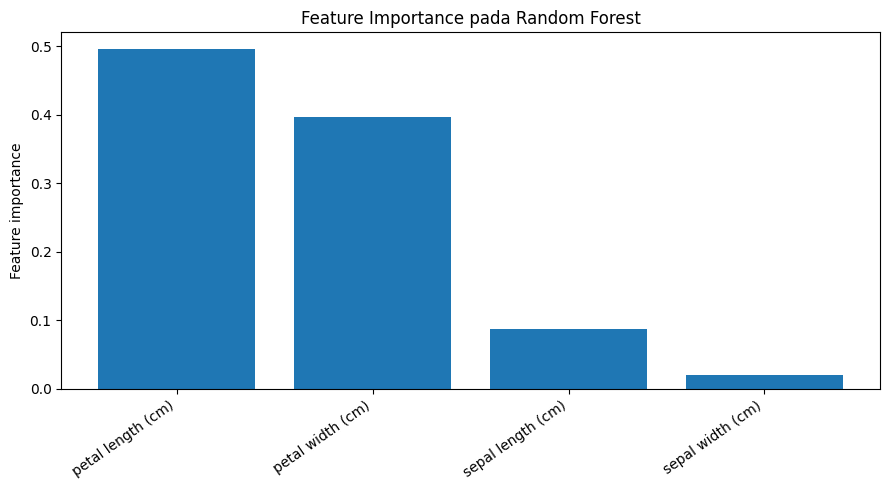

               fitur  importance
0  petal length (cm)    0.495780
1   petal width (cm)    0.397142
2  sepal length (cm)    0.087272
3   sepal width (cm)    0.019806


In [6]:
importances = rf_model.feature_importances_
order = np.argsort(importances)[::-1]

plt.figure(figsize=(9, 5))
plt.bar([iris.feature_names[i] for i in order], importances[order])
plt.ylabel("Feature importance")
plt.title("Feature Importance pada Random Forest")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "fitur": np.array(iris.feature_names)[order],
    "importance": importances[order]
}))

**Interpretasi feature importance.** Nilai lebih besar menunjukkan bahwa fitur tersebut lebih banyak berkontribusi terhadap pengurangan impurity di seluruh pohon. Ini merupakan ukuran kepentingan model, bukan bukti hubungan sebab-akibat. Fitur yang berkorelasi juga dapat berbagi atau mengaburkan kepentingan.

## 3. Gradient Boosting Machines

### Ringkasan

**Gradient Boosting** membangun model secara berurutan. Setiap model baru berupaya memperbaiki kesalahan model sebelumnya, lalu prediksi digabungkan menjadi model yang lebih kuat. Berbeda dari Random Forest yang melatih banyak pohon relatif independen, boosting bergantung pada urutan pembelajaran.

Parameter utama antara lain `n_estimators`, `learning_rate`, dan `max_depth`. `learning_rate` yang lebih kecil biasanya membutuhkan lebih banyak estimator. Model yang terlalu kompleks atau terlalu banyak iterasi dapat mengalami overfitting.

In [7]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=2, random_state=2024
)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting accuracy:", round(accuracy_score(y_test, y_pred_gb), 3))
print(classification_report(y_test, y_pred_gb, target_names=iris.target_names))

Gradient Boosting accuracy: 0.911
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



**Membaca hasil.** Nilai metrik perlu dibandingkan dengan model dasar pada data uji yang sama. Gradient Boosting dapat menangkap pola kompleks, tetapi memerlukan pemilihan parameter yang hati-hati. Skor yang lebih tinggi pada satu split saja belum cukup untuk menyimpulkan model terbaik.

In [8]:
# Bandingkan tiga pendekatan pada split data yang sama
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Gradient Boosting"],
    "Train accuracy": [
        tree_model.score(X_train, y_train),
        rf_model.score(X_train, y_train),
        gb_model.score(X_train, y_train)
    ],
    "Test accuracy": [
        tree_model.score(X_test, y_test),
        rf_model.score(X_test, y_test),
        gb_model.score(X_test, y_test)
    ]
})
comparison.round(3)

,Model,Train accuracy,Test accuracy
0,Decision Tree,1.0,0.911
1,Random Forest,1.0,0.956
2,Gradient Boosting,1.0,0.911


**Interpretasi perbandingan.** Perhatikan selisih antara train accuracy dan test accuracy, bukan hanya test accuracy. Skor training yang sangat tinggi dengan skor test lebih rendah dapat mengindikasikan overfitting. Untuk estimasi yang lebih andal, gunakan cross-validation.

## 4. Hyperparameter Tuning for Trees and Ensembles

### Ringkasan

**Hyperparameter tuning** mencari konfigurasi model yang memberikan performa validasi terbaik. `GridSearchCV` mencoba seluruh kombinasi yang ditentukan, sedangkan `RandomizedSearchCV` mengambil sejumlah kombinasi secara acak sehingga dapat lebih hemat waktu untuk ruang pencarian yang besar.

Untuk pohon dan ensemble, parameter yang umum dicoba antara lain `max_depth`, `min_samples_leaf`, `n_estimators`, dan `max_features`. Gunakan cross-validation pada data training dan simpan test set untuk evaluasi akhir.

In [9]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "max_depth": [2, 3, 4, None],
    "min_samples_leaf": [1, 2, 4],
    "n_estimators": [100, 200]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=2024, n_jobs=-1),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("Rata-rata skor CV terbaik:", round(grid_search.best_score_, 3))
print("Akurasi test:", round(grid_search.best_estimator_.score(X_test, y_test), 3))

Parameter terbaik: {'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 200}
Rata-rata skor CV terbaik: 0.952
Akurasi test: 0.956


**Membaca hasil.** `best_params_` adalah kombinasi dengan skor cross-validation terbaik, sedangkan `best_score_` adalah rata-rata skor validasi pada kombinasi tersebut. Skor test dihitung setelah pemilihan parameter selesai. Hindari menggunakan test set berulang kali untuk menentukan parameter karena dapat membuat evaluasi terlalu optimistis.

In [10]:
cv_results = pd.DataFrame(grid_search.cv_results_)
summary = cv_results[[
    "param_max_depth", "param_min_samples_leaf", "param_n_estimators",
    "mean_train_score", "mean_test_score", "std_test_score"
]].sort_values("mean_test_score", ascending=False)
summary.head(10).round(3)

,param_max_depth,param_min_samples_leaf,param_n_estimators,mean_train_score,mean_test_score,std_test_score
1,2,1,200,0.981,0.952,0.03
3,2,2,200,0.981,0.952,0.03
5,2,4,200,0.981,0.952,0.03
23,None,4,200,0.988,0.952,0.03
16,4,4,100,0.986,0.952,0.03
17,4,4,200,0.986,0.952,0.03
22,None,4,100,0.986,0.952,0.03
11,3,4,200,0.983,0.952,0.03
19,None,1,200,1.000,0.952,0.03
18,None,1,100,1.000,0.952,0.03


**Catatan interpretasi.** Skor validasi yang hampir sama pada beberapa konfigurasi dapat menjadi alasan memilih model yang lebih sederhana atau lebih cepat. Perbedaan antara `mean_train_score` dan `mean_test_score` membantu menilai apakah model terlalu menyesuaikan diri pada data training.

## 5. Comparing Ensemble Methods

### Ringkasan

Bab ini membandingkan pendekatan ensemble utama:

- **Bagging / Random Forest:** melatih banyak pohon dengan variasi sampel dan fitur; umumnya efektif untuk mengurangi varians.
- **Boosting / Gradient Boosting:** melatih model secara berurutan untuk memperbaiki kesalahan sebelumnya.
- **Stacking:** menggabungkan prediksi beberapa model dasar menggunakan model tingkat kedua (*final estimator*).

Tidak ada metode yang selalu paling unggul. Bandingkan model pada pembagian data yang konsisten dan, bila memungkinkan, gunakan cross-validation.

In [11]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

stack_model = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=2024, n_jobs=-1)),
        ("gb", GradientBoostingClassifier(n_estimators=100, random_state=2024)),
        ("tree", DecisionTreeClassifier(max_depth=4, random_state=2024))
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
    n_jobs=-1
)
stack_model.fit(X_train, y_train)

models = {
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "Stacking": stack_model
}
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro")
    })
comparison_ensemble = pd.DataFrame(rows).sort_values("Accuracy", ascending=False)
comparison_ensemble.round(3)

,Model,Accuracy,Macro F1
1,Random Forest,0.956,0.956
0,Decision Tree,0.911,0.911
2,Gradient Boosting,0.911,0.911
3,Stacking,0.911,0.911


**Interpretasi.** Tabel menampilkan accuracy dan macro F1 pada test set yang sama. Macro F1 menghitung F1 tiap kelas lalu merata-ratakannya, sehingga setiap kelas mendapat bobot sama. Stacking bisa membantu ketika model dasar memiliki kekuatan yang saling melengkapi, tetapi prosesnya lebih kompleks dan tidak menjamin hasil lebih baik.

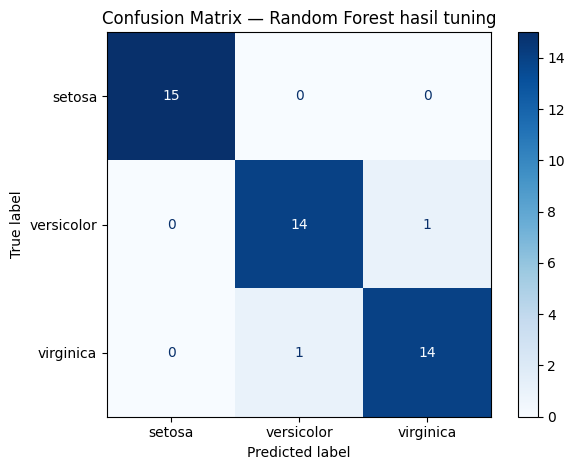

In [12]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_, X_test, y_test,
    display_labels=iris.target_names, cmap="Blues"
)
plt.title("Confusion Matrix — Random Forest hasil tuning")
plt.tight_layout()
plt.show()

### Praktik terbaik

1. Mulai dengan model sederhana sebagai baseline.
2. Pisahkan data training dan test sebelum tuning; jangan memilih parameter berdasarkan test set.
3. Gunakan cross-validation untuk membandingkan konfigurasi secara lebih stabil.
4. Kendalikan kompleksitas pohon melalui parameter seperti `max_depth` dan `min_samples_leaf`.
5. Gunakan feature importance sebagai alat bantu interpretasi, bukan sebagai bukti kausal.
6. Pilih metrik sesuai kebutuhan masalah; accuracy saja kurang informatif ketika kelas tidak seimbang.
7. Pertimbangkan waktu komputasi dan kemudahan interpretasi selain performa.

## Kesimpulan

Decision Tree mudah dijelaskan tetapi rentan overfitting. Random Forest menggabungkan banyak pohon untuk meningkatkan stabilitas, sementara Gradient Boosting membangun pohon berurutan untuk memperbaiki prediksi. Stacking menggabungkan beragam model melalui estimator tingkat kedua. Pemilihan model yang tepat perlu didasarkan pada evaluasi yang konsisten, validasi silang, tuning parameter, serta kebutuhan interpretasi dan komputasi.

### Latihan mandiri

1. Ubah `max_depth` pada Decision Tree dan bandingkan train accuracy dengan test accuracy.
2. Uji beberapa nilai `n_estimators` dan `max_features` pada Random Forest.
3. Ubah `learning_rate` dan `n_estimators` pada Gradient Boosting, lalu amati dampaknya.
4. Tambahkan parameter lain ke `GridSearchCV` dan catat perubahan `best_params_`.
5. Bandingkan Random Forest, Gradient Boosting, dan Stacking menggunakan dataset klasifikasi lain dari `sklearn.datasets`.
6. Jelaskan mengapa test set tidak sebaiknya dipakai berulang kali selama proses tuning.